# Linear Regression from Scratch to Autograd in PyTorch

This notebook demonstrates the implementation of a simple linear regression model to predict Celsius temperature values from raw measurements. The process starts with a fully manual calculation of gradients and manually updated parameters, and progresses into utilizing PyTorch's native **Autograd**, **Optimizers**, and **Dataset Splitting**.

In [ ]:
import torch

## Phase 1: Manual Gradient Descent and Parameter Tuning

In this section, we manually define our model, compute loss, analyze rate of change, and implement analytical derivatives without using PyTorch's automatic differentiation mechanisms.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

cuda


In [ ]:
t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]
t_c = torch.tensor(t_c)
t_u = torch.tensor(t_u)

Text(0.5, 0, 'Measurement')

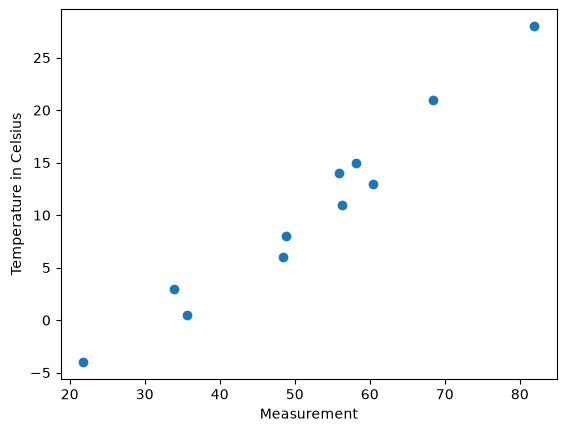

In [ ]:
plt.scatter(t_u, t_c)
plt.ylabel("Temperature in Celsius")
plt.xlabel("Measurement")

In [ ]:
#t_c = w * t_u + b

In [ ]:
def model(t_u, w, b):
    return w * t_u + b

In [ ]:
def loss(t_p, t_c):
    squared_diffs = (t_p - t_c) ** 2
    return squared_diffs.mean()

In [ ]:
w = torch.ones(())
b = torch.zeros(())

t_p = model(t_u, w, b)
t_p

tensor([35.7000, 55.9000, 58.2000, 81.9000, 56.3000, 48.9000, 33.9000, 21.8000,
        48.4000, 60.4000, 68.4000])

In [ ]:
losses = loss(t_p, t_c)
losses

tensor(1763.8848)

In [ ]:
w.shape

torch.Size([])

In [ ]:
delta = 0.1

loss_rate_of_change_w = (loss(model(t_u, w + delta, b), t_c) - loss(model(t_u, w - delta, b), t_c)) / (2.0 * delta)

In [ ]:
loss_rate_of_change_w

tensor(4517.2974)

In [ ]:
learning_rate = 1e-2

w = w - learning_rate * loss_rate_of_change_w

In [ ]:
w

tensor(-44.1730)

In [ ]:
loss_rate_of_change_b = (loss(model(t_u, w , b + delta), t_c) - loss(model(t_u, w , b- delta), t_c)) / (2.0 * delta)

In [ ]:
loss_rate_of_change_b

tensor(-4600.)

In [ ]:
b = b - learning_rate * loss_rate_of_change_b

In [ ]:
b

tensor(46.)

### Analytical Derivative Implementations

In [ ]:
def dloss_fn(t_p, t_c):
    dsq_loss = 2 * (t_p - t_c) / t_p.size(0)
    return dsq_loss

In [ ]:
def dmodel_dw(t_u,w,b):
    return t_u

def dmodel_db(t_u,w,b):
    return 1.0

Defining the gradient function

In [ ]:
def grad_fn(t_u, t_c, t_p, w, b):
    dloss_dtp = dloss_fn(t_p, t_c)
    dloss_dw = dloss_dtp * dmodel_dw(t_u, w, b)
    dloss_db = dloss_dtp + dmodel_db(t_u, w, b)
    return torch.stack([dloss_dw.sum(), dloss_db.sum()])

The training loop

In [ ]:
def training_loop(n_epochs, learning_rate, params,t_u, t_c):
    for epoch in range(1, n_epochs + 1):
        w, b = params

        #foreward Pass
        t_p = model(t_u, w, b)
        lossm = loss(t_p, t_c)

        #backward pass
        grad = grad_fn(t_u, t_c, t_p, w, b)

        params = params - learning_rate * grad

        print('Epoch %d, Loss %f' % (epoch, float(lossm)))
        print('Gradients: ' , grad)
        print('parameters: ', params )

    return params



In [ ]:
training_loop(
    n_epochs=20,
    learning_rate= 1e-2,
    params = torch.tensor([1.0 , 0.0]),
    t_u = t_u,
    t_c = t_c
)

Epoch 1, Loss 1763.884766
Gradients:  tensor([4517.2964,   93.6000])
parameters:  tensor([-44.1730,  -0.9360])
Epoch 2, Loss 5802991.000000
Gradients:  tensor([-261268.8125,   -4588.1904])
parameters:  tensor([2568.5151,   44.9459])
Epoch 3, Loss 19409696768.000000
Gradients:  tensor([15110263.0000,   266178.0625])
parameters:  tensor([-148534.1094,   -2616.8347])
Epoch 4, Loss 64921500909568.000000
Gradients:  tensor([-8.7389e+08, -1.5393e+07])
parameters:  tensor([8590368.0000,  151316.9531])
Epoch 5, Loss 217149199978856448.000000
Gradients:  tensor([5.0541e+10, 8.9026e+08])
parameters:  tensor([-4.9682e+08, -8.7513e+06])
Epoch 6, Loss 726319859491525361664.000000
Gradients:  tensor([-2.9230e+12, -5.1488e+10])
parameters:  tensor([2.8733e+10, 5.0613e+08])
Epoch 7, Loss 2429391518799244432506880.000000
Gradients:  tensor([1.6905e+14, 2.9778e+12])
parameters:  tensor([-1.6618e+12, -2.9271e+10])
Epoch 8, Loss 8125819098667954704719282176.000000
Gradients:  tensor([-9.7768e+15, -1.7222e

tensor([1.3458e+35, 2.3705e+33])

In [ ]:
training_loop(
    n_epochs=20,
    learning_rate= 1e-4,
    params = torch.tensor([1.0 , 0.0]),
    t_u = t_u,
    t_c = t_c
)

Epoch 1, Loss 1763.884766
Gradients:  tensor([4517.2964,   93.6000])
parameters:  tensor([ 0.5483, -0.0094])
Epoch 2, Loss 323.051147
Gradients:  tensor([1859.4354,   46.7821])
parameters:  tensor([ 0.3623, -0.0140])
Epoch 3, Loss 78.902031
Gradients:  tensor([765.3057,  27.5090])
parameters:  tensor([ 0.2858, -0.0168])
Epoch 4, Loss 37.533199
Gradients:  tensor([314.8987,  19.5749])
parameters:  tensor([ 0.2543, -0.0187])
Epoch 5, Loss 30.522820
Gradients:  tensor([129.4851,  16.3086])
parameters:  tensor([ 0.2414, -0.0204])
Epoch 6, Loss 29.332775
Gradients:  tensor([53.1583, 14.9639])
parameters:  tensor([ 0.2360, -0.0219])
Epoch 7, Loss 29.128191
Gradients:  tensor([21.7377, 14.4102])
parameters:  tensor([ 0.2339, -0.0233])
Epoch 8, Loss 29.090248
Gradients:  tensor([ 8.8032, 14.1821])
parameters:  tensor([ 0.2330, -0.0247])
Epoch 9, Loss 29.080391
Gradients:  tensor([ 3.4786, 14.0881])
parameters:  tensor([ 0.2326, -0.0261])
Epoch 10, Loss 29.075239
Gradients:  tensor([ 1.2867, 14

tensor([ 0.2327, -0.0416])

Normalizing the input

In [ ]:
t_un = 0.1 * t_u

params = training_loop(
    n_epochs=150,
    learning_rate= 1e-2,
    params = torch.tensor([1.0 , 0.0]),
    t_u = t_un,
    t_c = t_c
)

Epoch 1, Loss 80.364342
Gradients:  tensor([-77.6140,   0.3600])
parameters:  tensor([ 1.7761, -0.0036])
Epoch 2, Loss 37.849514
Gradients:  tensor([-32.0019,   8.3936])
parameters:  tensor([ 2.0962, -0.0875])
Epoch 3, Loss 30.567572
Gradients:  tensor([-14.0492,  11.5411])
parameters:  tensor([ 2.2367, -0.2029])
Epoch 4, Loss 28.957104
Gradients:  tensor([-6.9817, 12.7658])
parameters:  tensor([ 2.3065, -0.3306])
Epoch 5, Loss 28.311548
Gradients:  tensor([-4.1979, 13.2338])
parameters:  tensor([ 2.3484, -0.4629])
Epoch 6, Loss 27.851494
Gradients:  tensor([-3.0999, 13.4040])
parameters:  tensor([ 2.3794, -0.5970])
Epoch 7, Loss 27.436340
Gradients:  tensor([-2.6653, 13.4571])
parameters:  tensor([ 2.4061, -0.7316])
Epoch 8, Loss 27.036488
Gradients:  tensor([-2.4918, 13.4641])
parameters:  tensor([ 2.4310, -0.8662])
Epoch 9, Loss 26.644258
Gradients:  tensor([-2.4211, 13.4530])
parameters:  tensor([ 2.4552, -1.0007])
Epoch 10, Loss 26.257238
Gradients:  tensor([-2.3908, 13.4347])
par

In [ ]:
params

tensor([  5.4341, -17.8622])

In [ ]:
t_p = model(t_un, *params)

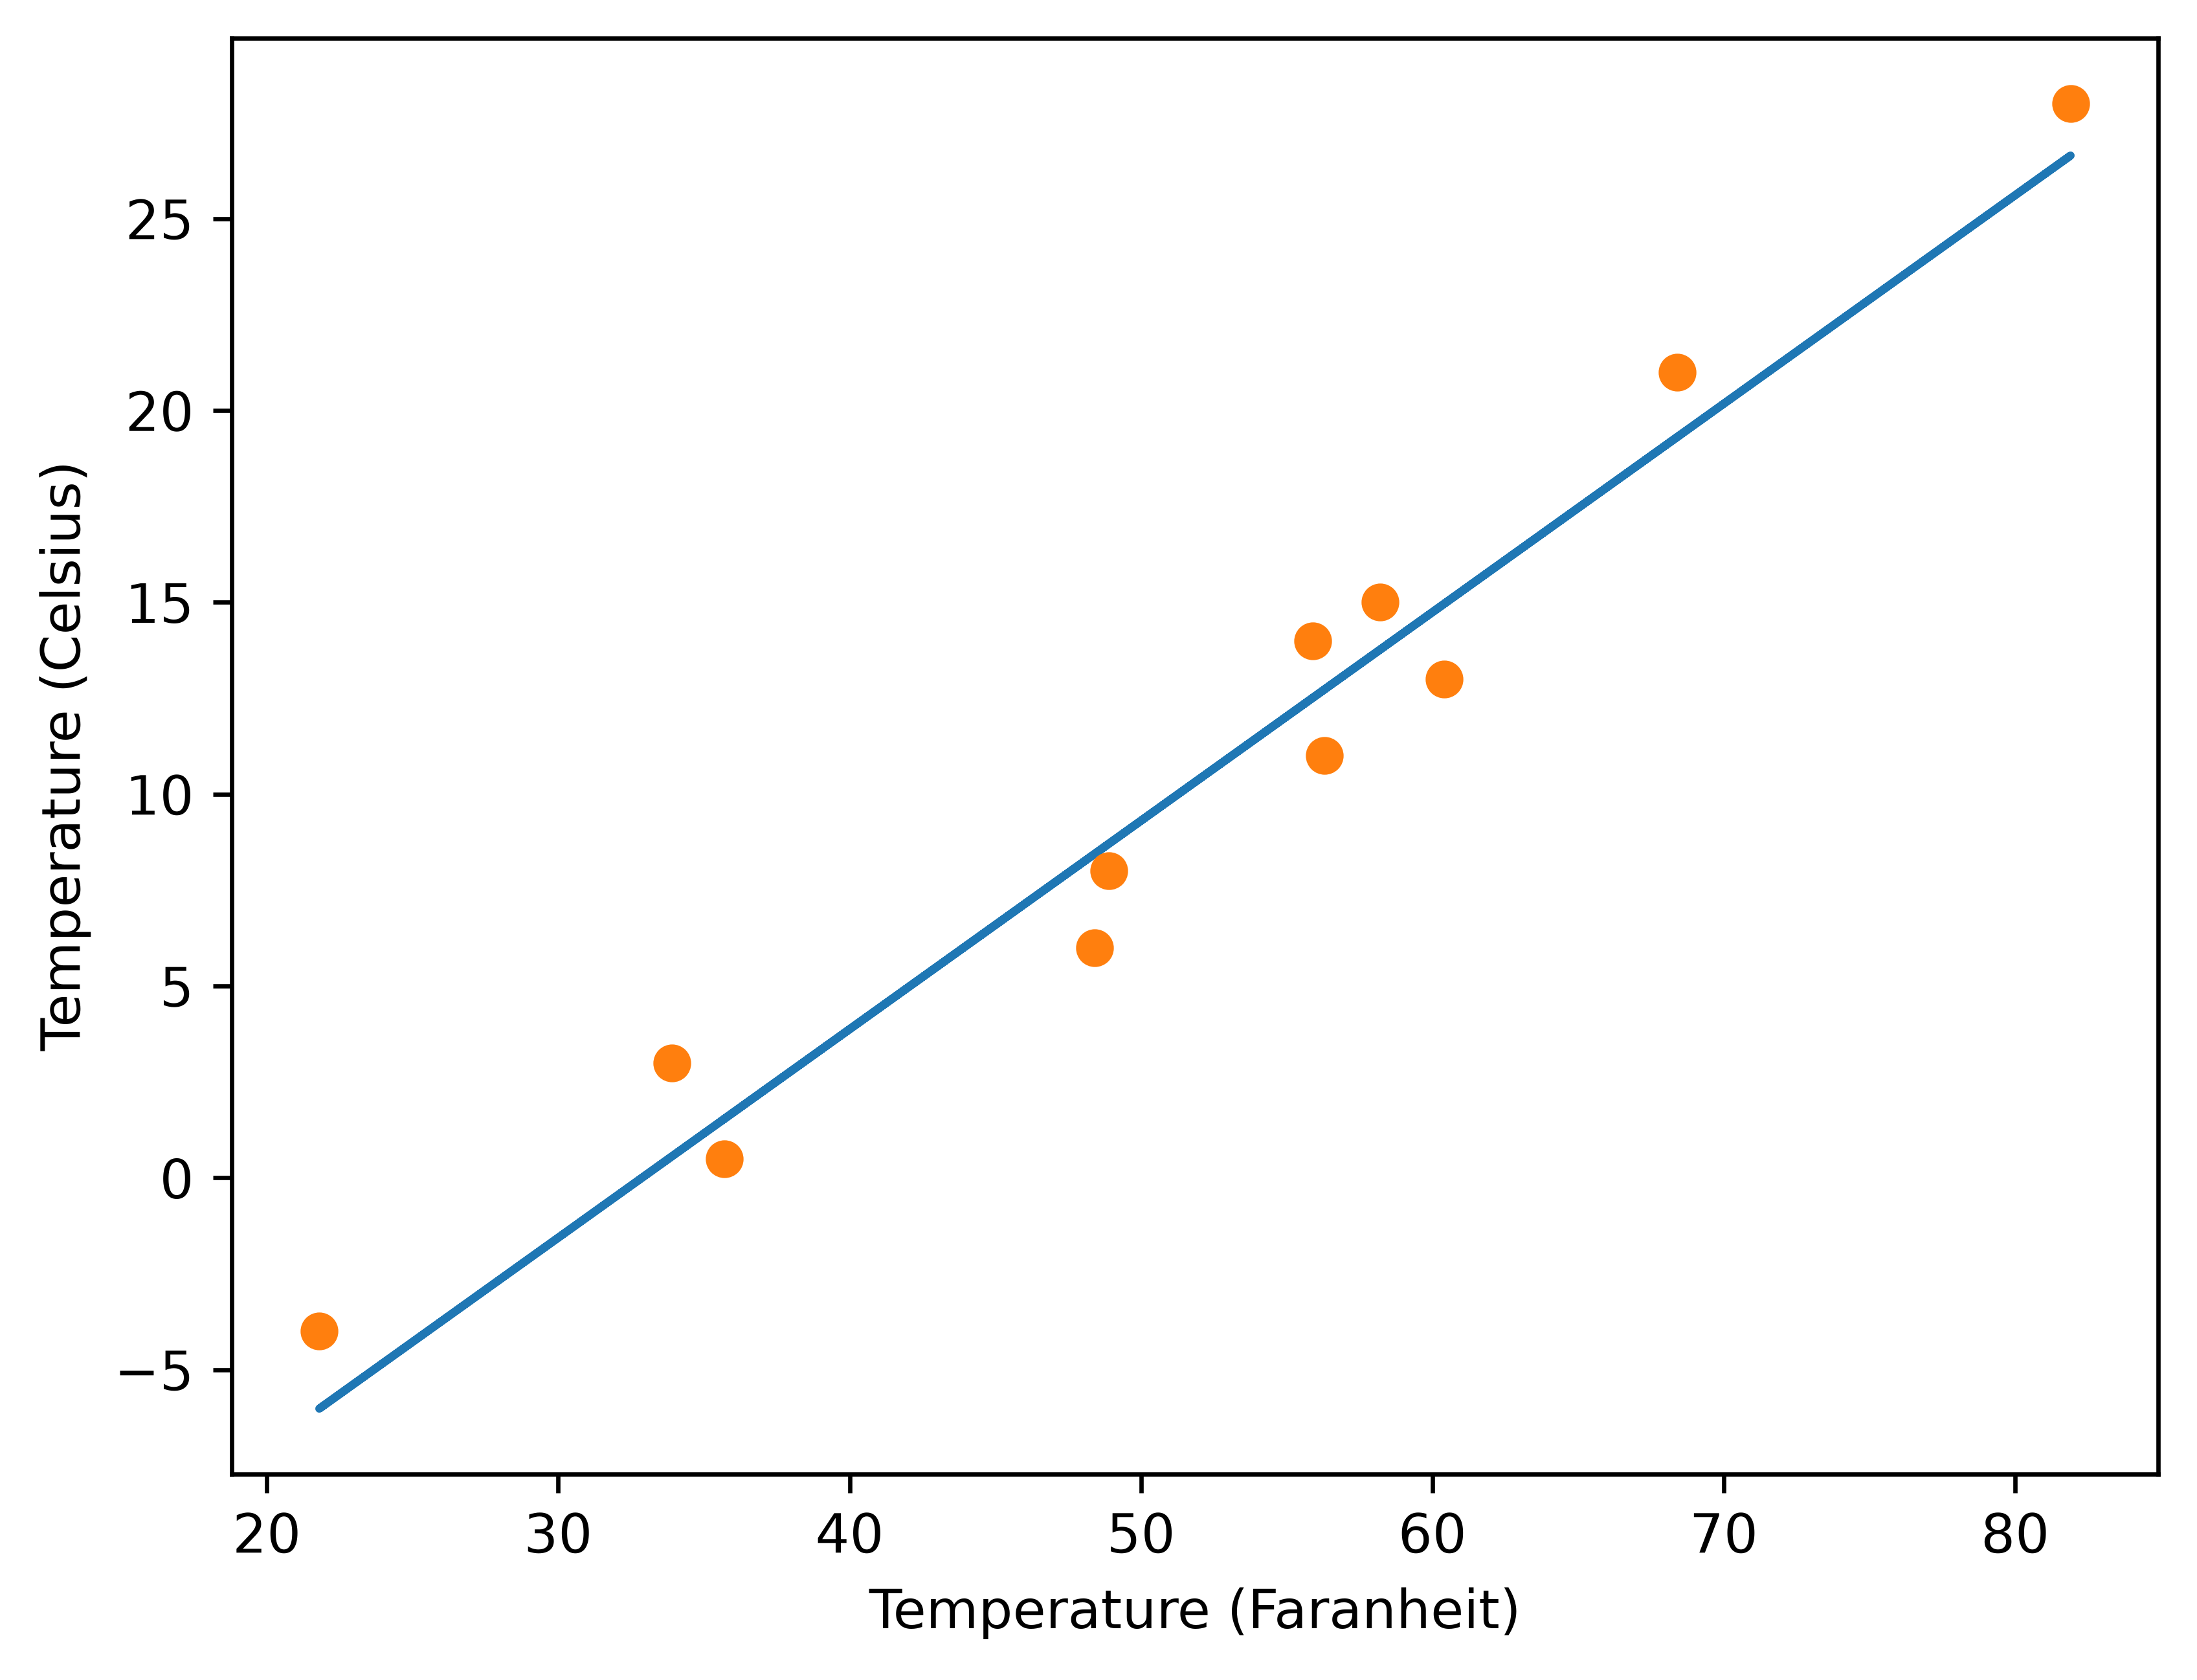

In [ ]:
%matplotlib inline

fig = plt.figure(dpi=600)
plt.xlabel("Temperature (Faranheit)")
plt.ylabel("Temperature (Celsius)")
plt.plot(t_u.numpy(), t_p.detach().numpy())
plt.plot(t_u.numpy(), t_c.numpy(), 'o')

### Now Using PyTorch Autograd

## Phase 2: Harnessing PyTorch Autograd

We transition to using PyTorch's dynamic computational graphs (`autograd`) to automatically compute gradients via `.backward()` instead of calculating them manually.

In [ ]:
params = torch.tensor([1.0, 0.0], requires_grad =True)

In [ ]:
params.grad is None

True

In [ ]:
loss_new = loss(model(t_u, *params), t_c)
loss_new.backward()

In [ ]:
params.grad

tensor([4517.2969,   82.6000])

In [ ]:
def training_loop(n_epochs, learning_rate, params, t_u, t_c):
    for epoch in range(1, n_epochs + 1):
        if params.grad is not None:
            params.grad.zero_()

        t_p = model(t_u, *params)
        loss_n = loss(t_p, t_c)
        loss_n.backward()

        with torch.no_grad():
            params -= learning_rate * params.grad

        if epoch % 500 == 0:
            print('Epoch %d , Loss %f ' % (epoch, float(loss_n)))

    return params

In [ ]:
training_loop(
n_epochs = 5000,
learning_rate = 1e-2,
params = torch.tensor([1.0, 0.0], requires_grad=True),
t_u = t_un,
t_c = t_c)

Epoch 500 , Loss 7.860115 
Epoch 1000 , Loss 3.828538 
Epoch 1500 , Loss 3.092191 
Epoch 2000 , Loss 2.957698 
Epoch 2500 , Loss 2.933134 
Epoch 3000 , Loss 2.928648 
Epoch 3500 , Loss 2.927830 
Epoch 4000 , Loss 2.927679 
Epoch 4500 , Loss 2.927652 
Epoch 5000 , Loss 2.927647 


tensor([  5.3671, -17.3012], requires_grad=True)

In [ ]:
import torch.optim as optim

dir(optim)

['ASGD',
 'Adadelta',
 'Adagrad',
 'Adam',
 'AdamW',
 'Adamax',
 'LBFGS',
 'NAdam',
 'Optimizer',
 'RAdam',
 'RMSprop',
 'Rprop',
 'SGD',
 'SparseAdam',
 '__builtins__',
 '__cached__',
 '__doc__',
 '__file__',
 '__loader__',
 '__name__',
 '__package__',
 '__path__',
 '__spec__',
 '_functional',
 '_multi_tensor',
 'lr_scheduler',
 'swa_utils']

### Optimization with PyTorch Optimizers

Instead of updating parameters manually with `with torch.no_grad():`, we leverage built-in optimizers from `torch.optim` like SGD and Adam.

Using a Gradient Descent Optimizer

In [ ]:
params = torch.tensor([1.0, 0.0], requires_grad=True)
learning_rate = 1e-5
optimizer = optim.SGD([params], lr= learning_rate)

In [ ]:
loss_optim = loss(model(t_u, *params), t_c)
loss_optim.backward()

optimizer.step()

params

tensor([ 9.5483e-01, -8.2600e-04], requires_grad=True)

In [ ]:
def training_loop_with_optimizer(n_epochs, optimizer, params, t_u, t_c):
    for epoch in range(1, n_epochs + 1):
        loss_optim_new = loss(model(t_u, *params), t_c)

        optimizer.zero_grad()
        loss_optim_new.backward()
        optimizer.step()

        if epoch % 500 == 0:
            print('Epoch %d, Loss %f' % (epoch, float(loss_optim_new)))

    return params

In [ ]:
params = torch.tensor([1.0 ,0.0], requires_grad = True)
learning_rate = 1e-2
optimizer = optim.SGD([params], lr=learning_rate)


training_loop_with_optimizer(
    n_epochs=5000,
    optimizer=optimizer,
    params= params,
    t_u=t_un,
    t_c = t_c
)

Epoch 500, Loss 7.860115
Epoch 1000, Loss 3.828538
Epoch 1500, Loss 3.092191
Epoch 2000, Loss 2.957698
Epoch 2500, Loss 2.933134
Epoch 3000, Loss 2.928648
Epoch 3500, Loss 2.927830
Epoch 4000, Loss 2.927679
Epoch 4500, Loss 2.927652
Epoch 5000, Loss 2.927647


tensor([  5.3671, -17.3012], requires_grad=True)

Using Adam optimizer

In [ ]:
params = torch.tensor([1.0 ,0.0], requires_grad = True)
learning_rate = 1e-1
optimizer = optim.Adam([params], lr=learning_rate)


training_loop_with_optimizer(
    n_epochs=2000,
    optimizer=optimizer,
    params= params,
    t_u=t_u,
    t_c = t_c
)

Epoch 500, Loss 7.612898
Epoch 1000, Loss 3.086700
Epoch 1500, Loss 2.928579
Epoch 2000, Loss 2.927644


tensor([  0.5367, -17.3021], requires_grad=True)

### Training and Validation Splits

To prevent overfitting and evaluate generalization, we split the data into training and validation sets, and adjust our training loop to monitor both losses.

In [ ]:
n_samples = t_u.shape[0]
n_val = int(0.2 * n_samples)

shuffled_indices = torch.randperm(n_samples)
train_indices = shuffled_indices[:-n_val]
val_indices = shuffled_indices[-n_val:]

train_indices, val_indices

(tensor([ 6,  1,  3,  4,  8,  2,  0,  9, 10]), tensor([5, 7]))

In [ ]:
train_t_u = t_u[train_indices]
train_t_c = t_c[train_indices]

val_t_u = t_u[val_indices]
val_t_c = t_c[val_indices]

train_t_un = 0.1 * train_t_u
val_t_un = 0.1 * val_t_u

In [ ]:
def training_loop(n_epochs, optimizer, params, train_t_u, val_t_u, train_t_c, val_t_c):

    for epoch in range(1,n_epochs+1):
        train_t_p = model(train_t_u, *params)
        train_loss = loss(train_t_p, train_t_c)

        val_t_p = model(val_t_u, *params)
        val_loss = loss(val_t_p, val_t_c)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        if epoch <=3 or epoch % 500 == 0:
            print(f"Epoch {epoch}, Training loss {train_loss.item():.4f},"
                  f" Validation loss {val_loss.item():.4f}")

    return params

In [ ]:
params = torch.tensor([1.0, 0.0], requires_grad=True)
learning_rate = 1e-2
optimizer = optim.SGD([params], lr=learning_rate)

training_loop(
    n_epochs = 3000,
    optimizer = optimizer,
    params = params,
    train_t_u = train_t_un,
    val_t_u = val_t_un,
    train_t_c = train_t_c,
    val_t_c = val_t_c)

Epoch 1, Training loss 92.9048, Validation loss 23.9323
Epoch 2, Training loss 32.4664, Validation loss 36.4383
Epoch 3, Training loss 25.9949, Validation loss 46.3535
Epoch 500, Training loss 9.8406, Validation loss 11.4031
Epoch 1000, Training loss 5.1131, Validation loss 2.0225
Epoch 1500, Training loss 3.6758, Validation loss 0.9233
Epoch 2000, Training loss 3.2388, Validation loss 1.5555
Epoch 2500, Training loss 3.1059, Validation loss 2.2806
Epoch 3000, Training loss 3.0655, Validation loss 2.7949


tensor([  5.5415, -18.3100], requires_grad=True)